# Import Required Libraries

In [100]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
from sklearn.model_selection import KFold
from sklearn.model_selection import StratifiedKFold
from sklearn.model_selection import LeaveOneOut
from sklearn.model_selection import TimeSeriesSplit
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt

* This code imports the libraries needed for data handling, model building, testing, and charts.

# Part 1: Data Preparation & Regression Models
# Load the Dataset

In [101]:
df = pd.read_csv("Advanced_Regression_HousePrice.csv")

df.head()

,property_id,sale_date,area_sqft,bedrooms,bathrooms,location_score,property_age,distance_city_km,near_school,near_metro,crime_rate_index,house_price_inr
0,200001,2014-01-01,2181,6,4,8.1,21,3.8,0,0,4.84,35154898
1,200002,2019-12-01,2383,5,4,5.3,28,10.9,1,1,2.89,26710893
2,200003,2016-10-01,1047,3,3,5.9,7,27.5,0,1,4.04,11216242
3,200004,2013-03-01,1753,4,3,7.0,27,12.1,0,0,3.28,21984310
4,200005,2013-07-01,1728,4,4,10.0,32,1.4,0,1,3.84,25080429


* This helps us get a first look at the dataset and understand how the data is organised.

# Explore the Dataset

In [102]:
df.info()
df.describe()
df.columns

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3800 entries, 0 to 3799
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   property_id       3800 non-null   int64  
 1   sale_date         3800 non-null   object 
 2   area_sqft         3800 non-null   int64  
 3   bedrooms          3800 non-null   int64  
 4   bathrooms         3800 non-null   int64  
 5   location_score    3800 non-null   float64
 6   property_age      3800 non-null   int64  
 7   distance_city_km  3800 non-null   float64
 8   near_school       3800 non-null   int64  
 9   near_metro        3800 non-null   int64  
 10  crime_rate_index  3800 non-null   float64
 11  house_price_inr   3800 non-null   int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 356.4+ KB


Index(['property_id', 'sale_date', 'area_sqft', 'bedrooms', 'bathrooms',
       'location_score', 'property_age', 'distance_city_km', 'near_school',
       'near_metro', 'crime_rate_index', 'house_price_inr'],
      dtype='object')

* This step helps us understand the dataset before starting the analysis.

# Check Missing Values and Duplicates

In [103]:
df.isnull().sum()
df.duplicated().sum()

0

* This helps us check the quality of the data before model training.

# Separate Features and Target Variable

In [104]:
X = df.drop(columns=["property_id", "sale_date", "house_price_inr"])

y = df["house_price_inr"]

* Here, we separate the input features from the house price that we want to predict.

# Display Features and Target

In [105]:
print("Features:", X.columns.tolist())
print("Target:", y.name)

Features: ['area_sqft', 'bedrooms', 'bathrooms', 'location_score', 'property_age', 'distance_city_km', 'near_school', 'near_metro', 'crime_rate_index']
Target: house_price_inr


* This gives us a clear view of which columns will be used for prediction.

# Train-Test Split

In [106]:

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (3040, 9)
X_test: (760, 9)
y_train: (3040,)
y_test: (760,)


* The model learns from the training data and is evaluated using unseen testing data.

# Feature Scaling

In [107]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

print("Scaled Training Data:")
print(X_train_scaled[:5])

print("\nScaled Testing Data:")
print(X_test_scaled[:5])

Scaled Training Data:
[[ 1.28512054  1.88879002  2.70553664 -0.35028874  0.44204424 -0.28951867
  -1.10114404  1.05548439  1.51203809]
 [-1.37634755 -1.79523517 -1.68760052  1.08640551  0.27991424 -0.96104093
   0.9081464   1.05548439  0.10393003]
 [-0.03619995  0.41517994 -0.80897309  0.62666335 -0.93606074 -1.84622937
  -1.10114404 -0.9474323   0.20137695]
 [ 0.11955156 -1.05843013 -0.80897309  1.31627659 -0.93606074 -1.3273258
   0.9081464  -0.9474323   0.15752584]
 [-0.99295922 -1.05843013  0.06965435  0.74159889 -1.01712574  0.88564529
  -1.10114404  1.05548439  0.92735654]]

Scaled Testing Data:
[[-0.64893666 -1.05843013 -0.80897309 -1.32724083 -0.85499574  0.24464677
   0.9081464   1.05548439  2.42803917]
 [ 1.03865662  1.88879002  2.70553664 -1.32724083 -1.17925574  0.97721651
  -1.10114404  1.05548439 -0.49536855]
 [ 0.45159324  0.41517994  0.06965435 -0.46522428 -0.53073575  0.97721651
  -1.10114404  1.05548439  0.0162278 ]
 [ 0.17260976 -0.32162509 -0.80897309  0.45426004  2

* Scaling helps prevent features with larger values from having an unnecessary influence on the model.

# Ridge Regression

In [108]:
ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train_scaled, y_train)


,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' to shuffle the data.See :term:`Glossary ` for details... versionadded:: 0.17 `random_state` to support Stochastic Average Gradient.",None


* Ridge Regression uses regularisation to control large coefficients and reduce overfitting.

# Ridge Regression Prediction

In [109]:
ridge_pred = ridge_model.predict(X_test_scaled)
print("Ridge Predictions:")
print(ridge_pred[:10])

Ridge Predictions:
[11134946.68677967 25272917.924517   22687679.50412925 21896839.06189664
 31384400.42040604  3733829.95036273 28431721.72884927 29653241.31819226
 36851087.36746315  4790975.31774151]


* This step uses the trained model to estimate prices for the test data.

# Lasso Regression

In [110]:
lasso_model = Lasso(alpha=1.0)
lasso_model.fit(X_train_scaled, y_train)

,"alpha alpha: float, default=1.0Constant that multiplies the L1 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Lasso` object is not advised.Instead, you should use the :class:`LinearRegression` object.",1.0
,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"precompute precompute: bool or array-like of shape (n_features, n_features), default=FalseWhether to use a precomputed Gram matrix to speed upcalculations. The Gram matrix can also be passed as argument.For sparse input this option is always ``False`` to preserve sparsity.",False
,"copy_X copy_X: bool, default=TrueIf ``True``, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=1000The maximum number of iterations.",1000
,"tol tol: float, default=1e-4The tolerance for the optimization: if the updates are smaller or equal to``tol``, the optimization code checks the dual gap for optimality and continuesuntil it is smaller or equal to ``tol``, see Notes below.",0.0001
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fit asinitialization, otherwise, just erase the previous solution.See :term:`the Glossary `.",False
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.",False
,"random_state random_state: int, RandomState instance, default=NoneThe seed of the pseudo random number generator that selects a randomfeature to update. Used when ``selection`` == 'random'.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",None
,"selection selection: {'cyclic', 'random'}, default='cyclic'If set to 'random', a random coefficient is updated every iterationrather than looping over features sequentially by default. This(setting to 'random') often leads to significantly faster convergenceespecially when tol is higher than 1e-4.",'cyclic'


* Lasso Regression reduces less useful feature coefficients and can set some of them to zero.

# Lasso Regression Prediction

In [111]:
lasso_pred = lasso_model.predict(X_test_scaled)
print("Lasso Predictions:")
print(lasso_pred[:10])

Lasso Predictions:
[11134526.65452562 25268088.50784517 22689073.84301881 21899856.42659438
 31385060.21890061  3726902.29558137 28433847.40990411 29653666.0186829
 36856195.81337436  4788987.10859041]


* Here, we use the Lasso model to estimate house prices on unseen data.

# Hyperparameter Tuning

In [112]:
alpha_values = {
    "alpha": [0.01, 0.1, 1, 10, 100]
}
ridge_grid = GridSearchCV(
    Ridge(),
    alpha_values,
    cv=5,
    scoring="neg_mean_squared_error"
)
ridge_grid.fit(X_train_scaled, y_train)

print("Best Ridge Alpha:", ridge_grid.best_params_)


lasso_grid = GridSearchCV(
    Lasso(max_iter=10000),
    alpha_values,
    cv=5,
    scoring="neg_mean_squared_error"
)

lasso_grid.fit(X_train_scaled, y_train)
print("Best Lasso Alpha:", lasso_grid.best_params_)

Best Ridge Alpha: {'alpha': 1}
Best Lasso Alpha: {'alpha': 100}


* We test different alpha values to find settings that give better model performance.

# Best Ridge and Lasso Predictions

In [113]:
best_ridge = ridge_grid.best_estimator_
ridge_pred = best_ridge.predict(X_test_scaled)

best_lasso = lasso_grid.best_estimator_
lasso_pred = best_lasso.predict(X_test_scaled)

* This helps us compare predictions from the models with their selected settings.

# Compare Training and Testing Errors

In [114]:
print("Ridge Training Error:",
      mean_squared_error(y_train, best_ridge.predict(X_train_scaled)))

print("Ridge Validation Error:",
      mean_squared_error(y_test, ridge_pred))

print("Lasso Training Error:",
      mean_squared_error(y_train, best_lasso.predict(X_train_scaled)))

print("Lasso Validation Error:",
      mean_squared_error(y_test, lasso_pred))

Ridge Training Error: 6253047097253.315
Ridge Validation Error: 6545419443619.521
Lasso Training Error: 6253028410486.958
Lasso Validation Error: 6544107497269.08


* Comparing both results helps us understand how well the models perform on known and unseen data.

# Compare Model Coefficients

In [115]:
coefficient_comparison = pd.DataFrame({
    "Feature": X.columns,
    "Ridge Coefficients": best_ridge.coef_,
    "Lasso Coefficients": best_lasso.coef_
})

coefficient_comparison

print("Ridge R2 Score:", r2_score(y_test, ridge_pred))

print("Lasso R2 Score:", r2_score(y_test, lasso_pred))

Ridge R2 Score: 0.9187259491828799
Lasso R2 Score: 0.9187422395360456


* This helps us understand how both models handle different features and compare their performance.

# Part 2: Cross-Validation Techniques
# K-Fold Cross-Validation

In [116]:
model = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
kfold = KFold(n_splits=5, shuffle=True, random_state=42)

kfold_scores = cross_val_score(
    model, X_train, y_train,
    cv=kfold,
    scoring="neg_mean_squared_error"
)

print("K-Fold Scores:", -kfold_scores)
print("Average MSE:", -kfold_scores.mean())

K-Fold Scores: [6.31590383e+12 7.13457463e+12 6.08741750e+12 5.83257278e+12
 6.20906774e+12]
Average MSE: 6315907296139.587


* The model is tested on different data splits to check whether its performance remains consistent.

# Stratified K-Fold Cross-Validation

In [117]:
y_bins = pd.qcut(y_train, q=5, labels=False)

stratified = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=42
)

stratified_scores = cross_val_score(
    model, X_train, y_train,
    cv=stratified.split(X_train, y_bins),
    scoring="neg_mean_squared_error"
)

print("Stratified K-Fold Scores:", -stratified_scores)
print("Average MSE:", -stratified_scores.mean())

Stratified K-Fold Scores: [6.54620805e+12 6.04898164e+12 5.96794074e+12 5.97163809e+12
 6.96374879e+12]
Average MSE: 6299703463584.781


* This method tries to maintain a similar distribution of house-price groups in each fold.

# Leave-One-Out Cross-Validation

In [118]:
loo = LeaveOneOut()

loo_scores = cross_val_score(
    model, X_train, y_train,
    cv=loo,
    scoring="neg_mean_squared_error"
)

print("Leave-One-Out Average MSE:", -loo_scores.mean())

Leave-One-Out Average MSE: 6298363400179.592


* The model is trained on all records except one, and the remaining record is used for testing.

# Time Series Cross-Validation

In [119]:
# Sort dataset according to sale_date
df_sorted = df.sort_values("sale_date")

X_time = df_sorted.drop(
    columns=["property_id", "sale_date", "house_price_inr"]
)

y_time = df_sorted["house_price_inr"]

tscv = TimeSeriesSplit(n_splits=5)

time_scores = cross_val_score(
    model, X_time, y_time,
    cv=tscv,
    scoring="neg_mean_squared_error"
)

print("Time Series Scores:", -time_scores)
print("Average MSE:", -time_scores.mean())

Time Series Scores: [6.93118450e+12 6.08523654e+12 6.01805334e+12 6.05794853e+12
 6.80040323e+12]
Average MSE: 6378565228089.329


* This method keeps the data in chronological order, using earlier records for training and later records for testing.

# Compare Cross-Validation Results

In [120]:
cv_results = pd.DataFrame({
    "CV Technique": [
        "K-Fold",
        "Stratified K-Fold",
        "Leave-One-Out",
        "Time Series Split"
    ],
    "Average MSE": [
        -kfold_scores.mean(),
        -stratified_scores.mean(),
        -loo_scores.mean(),
        -time_scores.mean()
    ]
})

cv_results

,CV Technique,Average MSE
0,K-Fold,6.315907e+12
1,Stratified K-Fold,6.299703e+12
2,Leave-One-Out,6.298363e+12
3,Time Series Split,6.378565e+12


* This makes it easier to compare the results of different validation methods.

# Calculate RMSE

In [121]:
cv_results["RMSE"] = np.sqrt(cv_results["Average MSE"])

cv_results


,CV Technique,Average MSE,RMSE
0,K-Fold,6.315907e+12,2.513147e+06
1,Stratified K-Fold,6.299703e+12,2.509921e+06
2,Leave-One-Out,6.298363e+12,2.509654e+06
3,Time Series Split,6.378565e+12,2.525582e+06


* RMSE helps us understand prediction errors in the same unit as house prices.

# Visualise Cross-Validation Results

In [122]:
print("Cross-Validation Performance:")
print(cv_results)

print("\nBest CV Strategy:")

best_cv = cv_results.loc[
    cv_results["Average MSE"].idxmin()
]

print(best_cv["CV Technique"])

Cross-Validation Performance:
        CV Technique   Average MSE          RMSE
0             K-Fold  6.315907e+12  2.513147e+06
1  Stratified K-Fold  6.299703e+12  2.509921e+06
2      Leave-One-Out  6.298363e+12  2.509654e+06
3  Time Series Split  6.378565e+12  2.525582e+06

Best CV Strategy:
Leave-One-Out


* This comparison helps us identify which validation method gives the lowest average MSE.

# Best Cross-Validation Method

In [123]:
print("Best CV Strategy:", best_cv["CV Technique"])
print("Lowest MSE:", best_cv["Average MSE"])
print("Lowest RMSE:", best_cv["RMSE"])

Best CV Strategy: Leave-One-Out
Lowest MSE: 6298363400179.592
Lowest RMSE: 2509654.039938492


* This step highlights the validation method with the lowest average prediction error.

# Part 3: Decision Tree and Random Forest
# Decision Tree Regression

In [124]:
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)
print("Decision Tree Predictions:")
print(dt_pred[:10])

Decision Tree Predictions:
[12586636. 20745512. 23447175. 18020855. 33041597.  7741632. 30529234.
 25528365. 38406973.  7741632.]


* A Decision Tree learns patterns from the data by making a series of decisions.

# Decision Tree with Limited Depth

In [125]:
dt_model = DecisionTreeRegressor(
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)
print("Tree Depth:", dt_model.get_depth())
print("Number of Leaf Nodes:", dt_model.get_n_leaves())

Tree Depth: 5
Number of Leaf Nodes: 32


* Limiting the tree depth helps control model complexity and reduce overfitting.

# Random Forest Regression

In [126]:
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("Random Forest Predictions:")
print(rf_pred[:10])

Random Forest Predictions:
[12182078.12 19003244.81 23023109.17 21439182.41 31911284.73  7563791.13
 30329000.36 29378582.01 37380998.74  6915942.38]


* Random Forest combines predictions from multiple decision trees to produce a final prediction.

# Evaluate Tree-Based Models

In [127]:
dt_mse = mean_squared_error(y_test, dt_pred)
dt_rmse = np.sqrt(dt_mse)
dt_r2 = r2_score(y_test, dt_pred)

rf_mse = mean_squared_error(y_test, rf_pred)
rf_rmse = np.sqrt(rf_mse)
rf_r2 = r2_score(y_test, rf_pred)

* These metrics help us understand how accurately both models predict house prices.

# Compare Decision Tree and Random Forest

In [128]:
comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "MSE": [dt_mse, rf_mse],
    "RMSE": [dt_rmse, rf_rmse],
    "R2 Score": [dt_r2, rf_r2]
})

comparison

if rf_mse < dt_mse:
    print("Random Forest performs better.")
else:
    print("Decision Tree performs better.")

Random Forest performs better.


* This comparison helps identify which model produces smaller prediction errors.

# Part 4: Support Vector Regression
# SVR with Linear Kernel

In [129]:
svr_linear = SVR(kernel="linear")
svr_linear.fit(X_train_scaled, y_train)
linear_pred = svr_linear.predict(X_test_scaled)

print("Linear SVR MSE:", mean_squared_error(y_test, linear_pred))
print("Linear SVR R2:", r2_score(y_test, linear_pred))

Linear SVR MSE: 80689290813854.28
Linear SVR R2: -0.0019137166824763074


* This model tries to learn a linear relationship between the input features and house prices.

# SVR with RBF Kernel

In [130]:
svr_rbf = SVR(kernel="rbf")
svr_rbf.fit(X_train_scaled, y_train)
rbf_pred = svr_rbf.predict(X_test_scaled)

print("RBF SVR MSE:", mean_squared_error(y_test, rbf_pred))
print("RBF SVR R2:", r2_score(y_test, rbf_pred))

RBF SVR MSE: 80772044778137.69
RBF SVR R2: -0.002941267316384888


* The RBF kernel helps the model learn more complex, non-linear relationships in the data.

# SVR Hyperparameter Tuning

In [131]:
param_grid = {
    "C": [0.1, 1, 10, 100],
    "gamma": [0.01, 0.1, 1],
    "epsilon": [0.1, 0.5, 1]
}

svr = SVR(kernel="rbf")

grid_search = GridSearchCV(
    svr,
    param_grid,
    cv=5,
    scoring="neg_mean_squared_error"
)

grid_search.fit(X_train_scaled, y_train)

print("Best Parameters:", grid_search.best_params_)
print("Best Score:", -grid_search.best_score_)

Best Parameters: {'C': 100, 'epsilon': 0.1, 'gamma': 0.1}
Best Score: 74976230547029.12


* We test different parameter combinations to find the settings that work best for the model.

# Best SVR Model Prediction

In [132]:
best_svr = grid_search.best_estimator_

best_svr_pred = best_svr.predict(X_test_scaled)

print("Best SVR MSE:", mean_squared_error(y_test, best_svr_pred))
print("Best SVR R2:", r2_score(y_test, best_svr_pred))

Best SVR MSE: 80525595168103.05
Best SVR R2: 0.00011888158657646919


* This step checks how well the selected SVR model predicts house prices.

# Part 5: Model Evaluation and Comparison
# Linear Regression

In [133]:

# Linear Regression
lr_model = LinearRegression()
lr_model.fit(X_train_scaled, y_train)
lr_pred = lr_model.predict(X_test_scaled)

# Decision Tree and Random Forest predictions
# dt_pred and rf_pred are from Part E.

results = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree", "Random Forest",
              "Linear SVR", "RBF SVR"],
    "MSE": [
        mean_squared_error(y_test, lr_pred),
        mean_squared_error(y_test, dt_pred),
        mean_squared_error(y_test, rf_pred),
        mean_squared_error(y_test, linear_pred),
        mean_squared_error(y_test, best_svr_pred)
    ],
    "R2 Score": [
        r2_score(y_test, lr_pred),
        r2_score(y_test, dt_pred),
        r2_score(y_test, rf_pred),
        r2_score(y_test, linear_pred),
        r2_score(y_test, best_svr_pred)
    ]
})

print(results)

               Model           MSE  R2 Score
0  Linear Regression  6.543996e+12  0.918744
1      Decision Tree  9.385836e+12  0.883457
2      Random Forest  5.842748e+12  0.927451
3         Linear SVR  8.068929e+13 -0.001914
4            RBF SVR  8.052560e+13  0.000119


*  Linear Regression provides a basic model that we can use as a reference for comparison.

# Model Evaluation Metrics

In [134]:
models = {
    "Linear Regression": lr_pred,
    "Ridge Regression": ridge_pred,
    "Lasso Regression": lasso_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "Linear SVR": linear_pred,
    "RBF SVR": best_svr_pred
}

results = []

for name, prediction in models.items():
    mse = mean_squared_error(y_test, prediction)
    mae = mean_absolute_error(y_test, prediction)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_test, prediction)

    results.append([name, mse, mae, rmse, r2])

evaluation_df = pd.DataFrame(
    results,
    columns=["Model", "MSE", "MAE", "RMSE", "R2 Score"]
)

print(evaluation_df)

               Model           MSE           MAE          RMSE  R2 Score
0  Linear Regression  6.543996e+12  1.959378e+06  2.558123e+06  0.918744
1   Ridge Regression  6.545419e+12  1.959199e+06  2.558402e+06  0.918726
2   Lasso Regression  6.544107e+12  1.959385e+06  2.558145e+06  0.918742
3      Decision Tree  9.385836e+12  2.325304e+06  3.063631e+06  0.883457
4      Random Forest  5.842748e+12  1.778261e+06  2.417178e+06  0.927451
5         Linear SVR  8.068929e+13  6.990272e+06  8.982722e+06 -0.001914
6            RBF SVR  8.052560e+13  6.982673e+06  8.973605e+06  0.000119


* These evaluation metrics help us compare prediction errors and overall model performance.

# Compare Model Types

In [135]:
evaluation_df["Model Type"] = [
    "Linear", "Regularized Linear", "Regularized Linear",
    "Tree-Based", "Tree-Based", "SVR", "SVR"
]

comparison = evaluation_df.groupby("Model Type")[
    ["MSE", "MAE", "RMSE", "R2 Score"]
].mean()

print(comparison)

                             MSE           MAE          RMSE  R2 Score
Model Type                                                            
Linear              6.543996e+12  1.959378e+06  2.558123e+06  0.918744
Regularized Linear  6.544763e+12  1.959292e+06  2.558274e+06  0.918734
SVR                 8.060744e+13  6.986473e+06  8.978164e+06 -0.000897
Tree-Based          7.614292e+12  2.051783e+06  2.740405e+06  0.905454


* This gives us a broader view of how different types of regression models perform.

# Select the Best Model

In [136]:
best_model = evaluation_df.loc[evaluation_df["RMSE"].idxmin()]

print("Best Model:", best_model["Model"])
print("RMSE:", best_model["RMSE"])
print("R2 Score:", best_model["R2 Score"])

Best Model: Random Forest
RMSE: 2417177.7942502326
R2 Score: 0.9274509690787089


* A lower RMSE means the model has smaller prediction errors, so we select the model with the lowest value.

# Check Overfitting and Underfitting

In [137]:

train_predictions = {
    "Linear Regression": lr_model.predict(X_train_scaled),
    "Ridge Regression": ridge_model.predict(X_train_scaled),
    "Lasso Regression": lasso_model.predict(X_train_scaled),
    "Decision Tree": dt_model.predict(X_train),
    "Random Forest": rf_model.predict(X_train),
    "Linear SVR": svr_linear.predict(X_train_scaled),
    "RBF SVR": best_svr.predict(X_train_scaled)
}

test_predictions = {
    "Linear Regression": lr_pred,
    "Ridge Regression": ridge_pred,
    "Lasso Regression": lasso_pred,
    "Decision Tree": dt_pred,
    "Random Forest": rf_pred,
    "Linear SVR": linear_pred,
    "RBF SVR": best_svr_pred
}

for name in train_predictions:
    train_r2 = r2_score(y_train, train_predictions[name])
    test_r2 = r2_score(y_test, test_predictions[name])

    print("\n", name)
    print("Training R2:", train_r2)
    print("Testing R2:", test_r2)

    if train_r2 > test_r2 + 0.15:
        print("Possible Overfitting")
    elif train_r2 < 0.5 and test_r2 < 0.5:
        print("Possible Underfitting")
    else:
        print("Model has a reasonable fit")


 Linear Regression
Training R2: 0.9161856554543095
Testing R2: 0.9187436301496137
Model has a reasonable fit

 Ridge Regression
Training R2: 0.9161854041282822
Testing R2: 0.9187259491828799
Model has a reasonable fit

 Lasso Regression
Training R2: 0.9161856554542243
Testing R2: 0.9187422395360456
Model has a reasonable fit

 Decision Tree
Training R2: 0.8994312170146984
Testing R2: 0.8834566744111698
Model has a reasonable fit

 Random Forest
Training R2: 0.9893105387713592
Testing R2: 0.9274509690787089
Model has a reasonable fit

 Linear SVR
Training R2: -0.005827369548303762
Testing R2: -0.0019137166824763074
Possible Underfitting

 RBF SVR
Training R2: -0.0036303229073031407
Testing R2: 0.00011888158657646919
Possible Underfitting


* A large difference between training and testing scores may indicate overfitting.

# Final Model Evaluation

In [138]:
best_model = evaluation_df.loc[evaluation_df["RMSE"].idxmin()]

print("Best Performing Model:", best_model["Model"])
print("MSE:", best_model["MSE"])
print("MAE:", best_model["MAE"])
print("RMSE:", best_model["RMSE"])
print("R2 Score:", best_model["R2 Score"])

Best Performing Model: Random Forest
MSE: 5842748489016.419
MAE: 1778261.3448157895
RMSE: 2417177.7942502326
R2 Score: 0.9274509690787089


* This gives us a final overview of how well the selected model performs.

# Model Performance Visualisation

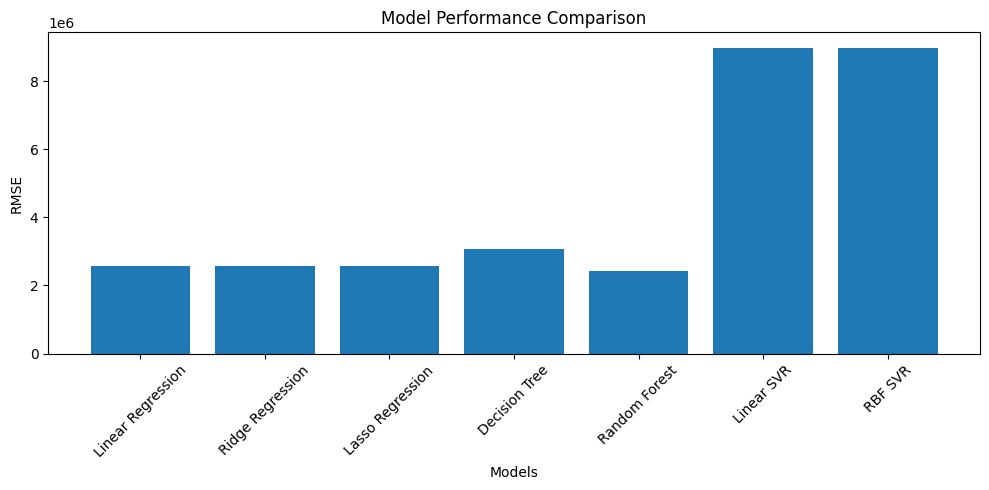

In [139]:
# Compare models using RMSE
plt.figure(figsize=(10, 5))
plt.bar(evaluation_df["Model"], evaluation_df["RMSE"])

plt.title("Model Performance Comparison")
plt.xlabel("Models")
plt.ylabel("RMSE")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

* The chart makes it easier to compare prediction errors. A lower RMSE indicates better performance.

# Final Project Summary

In [140]:
print("FINAL CONCLUSION")
print("----------------")

print("Best Model:", best_model["Model"])
print("RMSE:", best_model["RMSE"])
print("R2 Score:", best_model["R2 Score"])

print("\nThe project compared different regression models")
print("for house price prediction.")

print("Regularization helped control overfitting.")
print("Cross-validation helped evaluate model stability.")
print("The best model was selected based on evaluation metrics.")

FINAL CONCLUSION
----------------
Best Model: Random Forest
RMSE: 2417177.7942502326
R2 Score: 0.9274509690787089

The project compared different regression models
for house price prediction.
Regularization helped control overfitting.
Cross-validation helped evaluate model stability.
The best model was selected based on evaluation metrics.


* This final step summarises the project and highlights the model that performed best during evaluation.